# CS-317: Reinforcement Learning — Lab 9
## Learning to Act: SARSA and Q-learning
**BS AI-1**
**Muhammad Sikandar Hussain (502808)**

This notebook provides the loading-dock environment and helper functions. Complete every `# TODO` cell, run all cells top to bottom without errors, and answer the written questions in the markdown cells provided for them.

- Set your personal **SEED** (the last three digits of your roll number) in the first code cell below. Every random experiment must use it, and your written answers must refer to your own numbers.
- **Predict first** cells must be filled in *before* you run the code beneath them.
- Your code must learn only through `env.reset()` and `env.step()`; the rules of the dock are hidden.

Reinforcement-learning libraries may not be used. NumPy and Matplotlib only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=2, suppress=True)

In [2]:
# ---------------------------------------------------------------
# Personal seed: the last three digits of your roll number.
# Every random experiment in this notebook must use it.
# ---------------------------------------------------------------
SEED = 808          # Roll number 502808 -> last three digits: 808

assert SEED is not None, "Set SEED to the last three digits of your roll number before running the notebook."
print("SEED =", SEED)

SEED = 808


---
## Provided Starter Code

Run the cells in this section as-is. You do not need to modify them.

| Name | What it gives you |
|---|---|
| `DockEnv()` | `reset()` → `s` ; `step(a)` → `s2, r, done`. The rules are hidden. |
| `START`, `GOAL`, `EDGE` | cell 24, cell 31, and the dock-edge cells 25–30 |
| `test_route(env, Q)` | follows the best action of `Q` from S with **no exploration**; returns `reward`, `steps`, `path`, `reached`, `top_row` |
| `plot_route(Q, title)` | draws the grid, the best action in every cell, and the route from S |
| `moving_average(x, w=10)` | smooths a learning curve |

A Q table is an array of shape `(32, 4)`: one row per cell, one column per action (Up, Down, Left, Right).

In [3]:
# ---------------------------------------------------------------
# Warehouse loading dock (4 x 8 grid)
#
#        col: 0  1  2  3  4  5  6  7
#   row 0     .  .  .  .  .  .  .  .        cells are numbered row by row:
#   row 1     .  .  .  .  .  .  .  .        cell = 8 * row + col
#   row 2     .  .  .  .  .  .  .  .
#   row 3     S  X  X  X  X  X  X  G        S = start (cell 24), G = goal (cell 31)
#                                           X = dock edge (cells 25..30)
#
#   Actions: 0 = Up, 1 = Down, 2 = Left, 3 = Right
#   Every move costs -1. A move into the outer wall leaves the robot in place.
#   Driving onto the dock edge costs -100 and sends the robot back to S;
#   the episode continues. Reaching G ends the episode. No discounting (gamma = 1).
# ---------------------------------------------------------------

N_ROWS, N_COLS = 4, 8
N_STATES, N_ACTIONS = N_ROWS * N_COLS, 4
ACTIONS = ["Up", "Down", "Left", "Right"]
START, GOAL = 24, 31
EDGE = tuple(range(25, 31))
GAMMA = 1.0


class DockEnv:
    """The loading dock as an environment you can only ACT in.

    reset()       -> s                 the start cell (24)
    step(action)  -> s2, r, done       next cell, reward, end-of-episode flag

    The rules are hidden: reading env.P or env.R raises an error, as in Labs 7 and 8.
    """

    def __init__(self):
        self.__s = None

    def __getattr__(self, name):
        if name in ("P", "R", "transition_matrix"):
            raise AttributeError(f"The model is hidden: '{name}' is not available. "
                                 "This environment only offers reset() and step(action).")
        raise AttributeError(name)

    def reset(self):
        self.__s = START
        return self.__s

    def step(self, action):
        if self.__s is None or self.__s == GOAL:
            raise RuntimeError("Episode has ended (or not started): call reset() first.")
        r, c = divmod(self.__s, N_COLS)
        if action == 0:   r = max(r - 1, 0)
        elif action == 1: r = min(r + 1, N_ROWS - 1)
        elif action == 2: c = max(c - 1, 0)
        else:             c = min(c + 1, N_COLS - 1)
        s2 = r * N_COLS + c
        if s2 in EDGE:                       # drove onto the dock edge
            self.__s = START
            return START, -100.0, False
        self.__s = s2
        return s2, -1.0, s2 == GOAL


env = DockEnv()
print("Start cell:", env.reset())

Start cell: 24


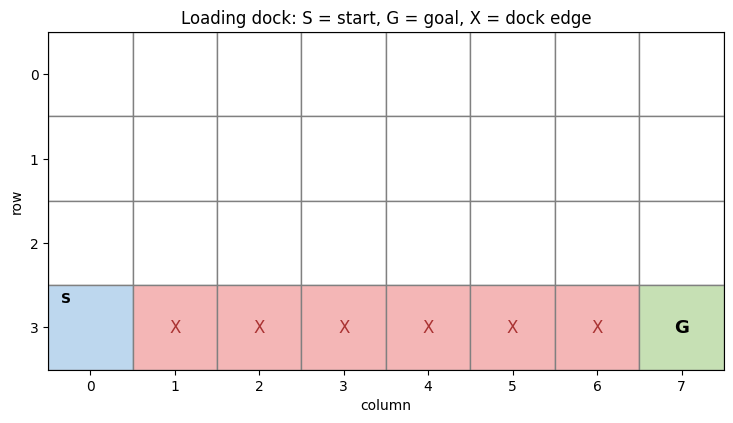

In [4]:
# ---------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------

def test_route(env, Q, max_steps=50):
    """Follows the greedy action argmax_a Q(s, a) from the start, with NO exploration.

    Returns a dict with
      'reward'  : total reward of the trip
      'steps'   : number of steps taken
      'path'    : list of visited cells, starting with the start cell
      'reached' : True if the goal was reached within max_steps
      'top_row' : the highest row the route climbs to (0 = top row); None if the goal was not reached
    """
    s = env.reset()
    path, total = [s], 0.0
    for _ in range(max_steps):
        a = int(np.argmax(Q[s]))
        s, r, done = env.step(a)
        total += r
        path.append(s)
        if done:
            rows = [p // N_COLS for p in path[1:-1]] or [N_ROWS - 1]
            return {"reward": total, "steps": len(path) - 1, "path": path,
                    "reached": True, "top_row": min(rows)}
    return {"reward": total, "steps": max_steps, "path": path, "reached": False, "top_row": None}


def plot_route(Q=None, title="", env=None):
    """Draws the grid with the greedy action of every cell (small grey arrows) and the
    route followed from S with no exploration (red line). With Q=None, only the layout is drawn."""
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for s in range(N_STATES):
        r, c = divmod(s, N_COLS)
        face = "#f4b6b6" if s in EDGE else ("#c6e0b4" if s == GOAL else ("#bdd7ee" if s == START else "white"))
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, facecolor=face, edgecolor="grey"))
        if s in EDGE:
            ax.text(c, r, "X", ha="center", va="center", fontsize=12, color="#a33")
            continue
        if s == GOAL:
            ax.text(c, r, "G", ha="center", va="center", fontsize=13, fontweight="bold")
            continue
        if s == START:
            ax.text(c - .35, r - .3, "S", fontsize=10, fontweight="bold")
        if Q is None:
            continue
        a = int(np.argmax(Q[s]))
        dx, dy = [(0, -.3), (0, .3), (-.3, 0), (.3, 0)][a]
        ax.annotate("", xy=(c + dx, r + dy), xytext=(c, r),
                    arrowprops=dict(arrowstyle="->", color="grey", lw=1.2))
    status = None
    if Q is not None:
        route = test_route(env if env is not None else DockEnv(), Q)
        xs = [p % N_COLS for p in route["path"]]
        ys = [p // N_COLS for p in route["path"]]
        ax.plot(xs, ys, color="crimson", lw=3, alpha=.8)
        status = f"{route['steps']} steps, reward {route['reward']:.0f}" if route["reached"] else "did not reach G"
    ax.set_xlim(-.5, N_COLS - .5); ax.set_ylim(N_ROWS - .5, -.5)
    ax.set_xticks(range(N_COLS)); ax.set_yticks(range(N_ROWS))
    ax.set_xlabel("column"); ax.set_ylabel("row")
    ax.set_title(title if status is None else f"{title}  (route: {status})")
    ax.set_aspect("equal"); plt.tight_layout(); plt.show()


def moving_average(x, w=10):
    """Smooths a learning curve: the average of each window of w consecutive values."""
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")


# Show the empty grid
plot_route(title="Loading dock: S = start, G = goal, X = dock edge")

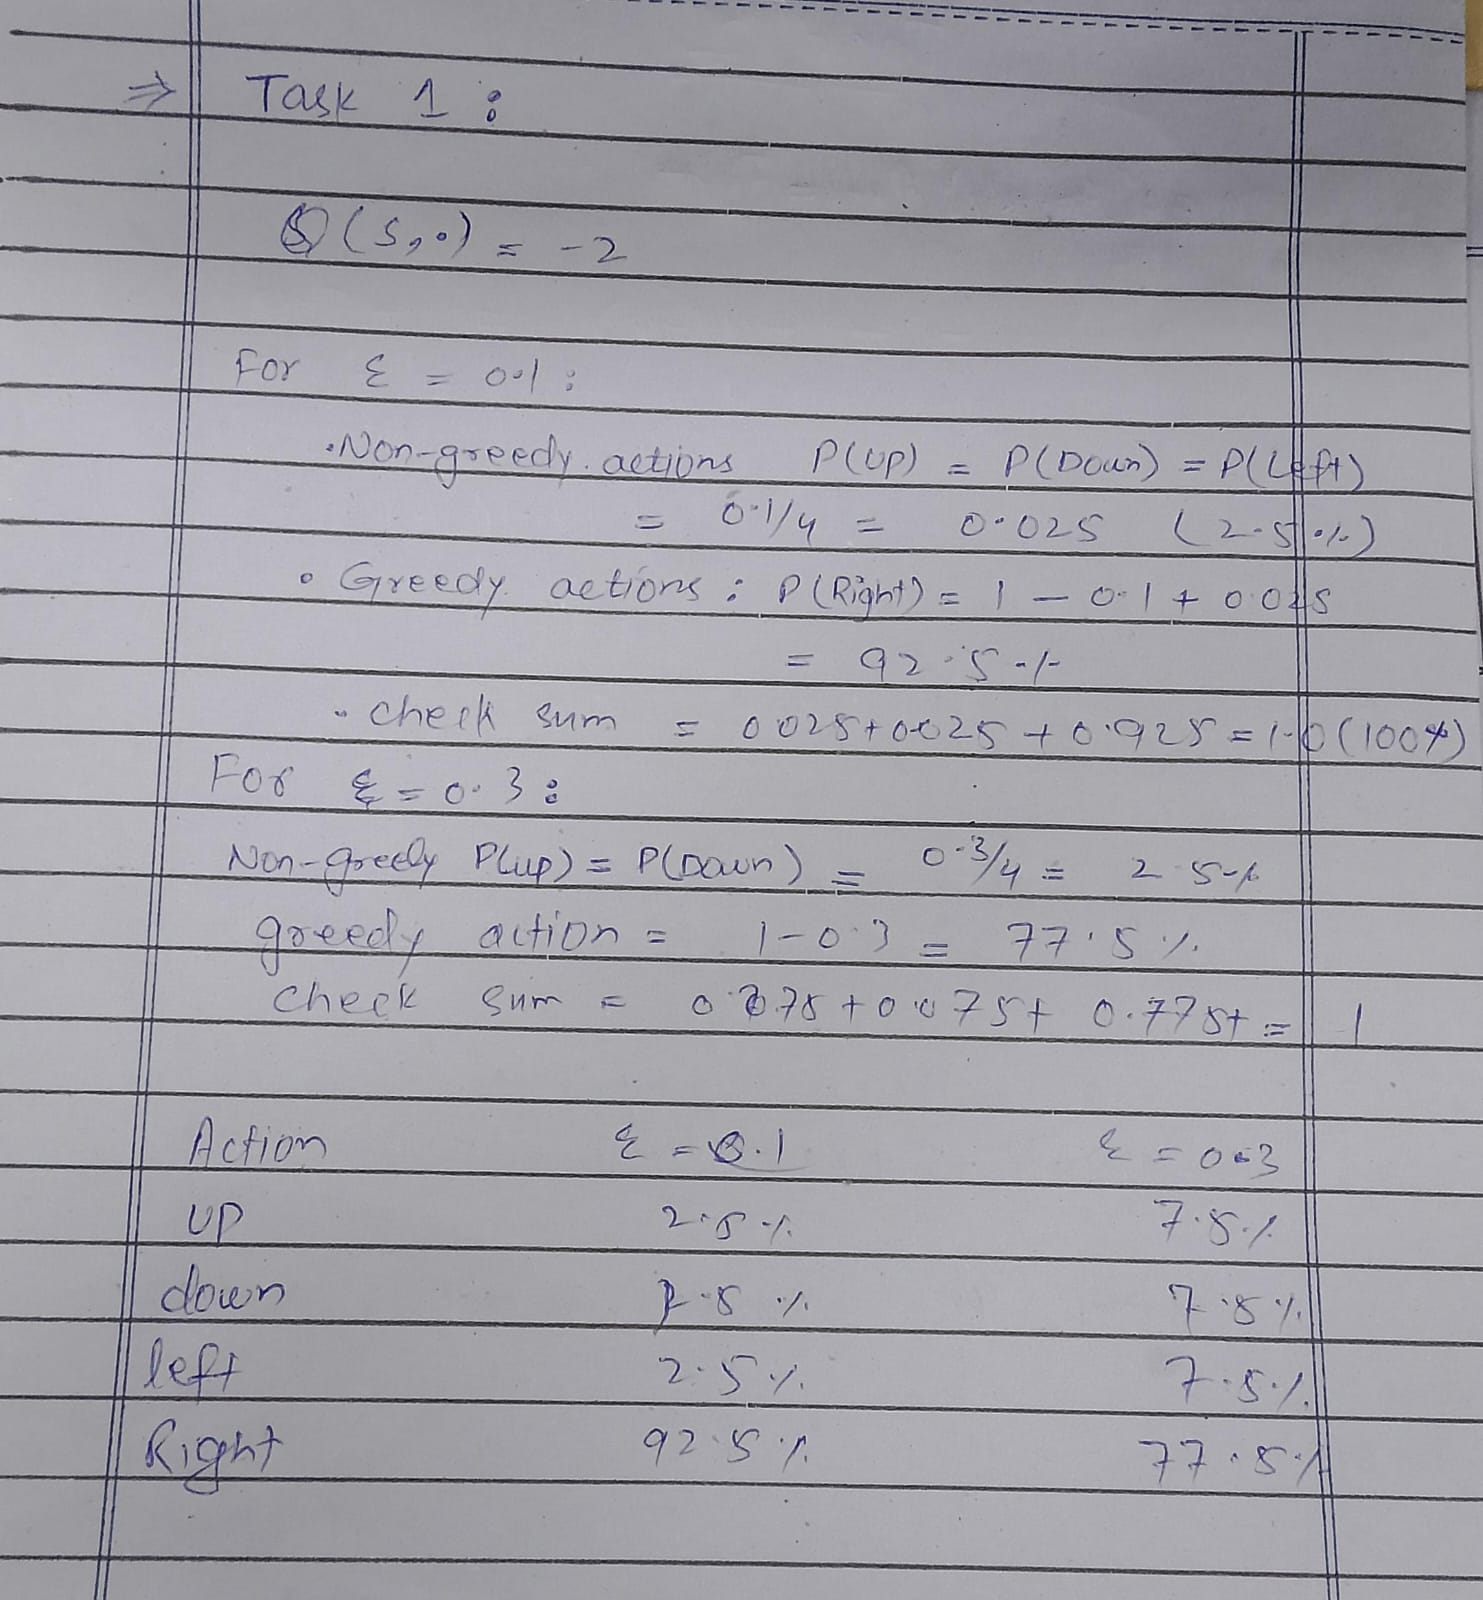

---
## Part 1: From Prediction to Control

Labs 7 and 8 **measured** how good a fixed policy was. In this lab the robot **improves its own behaviour**. To choose an action without knowing the rules, it learns an **action-value table** $Q(s, a)$: one number for every cell and every action.

**ε-greedy action choice.** With probability $1-\varepsilon$ the robot takes the action with the highest $Q(s,a)$ (ties broken at random); with probability $\varepsilon$ it takes a completely random action (any of the four, possibly the best one again).

### Task 1: Why Q, and ε-greedy

**(a)** In Lab 5, choosing the best action from $V$ required the rules. Explain why, and say what the robot must learn instead when the rules are hidden.

**Answer:**
In Lab 5, policy improvement using state-value function $V(s)$ required choosing the greedy action via one-step lookahead:
$$\pi'(s) = \arg\max_{a} \sum_{s', r} p(s', r \mid s, a) \left[ r + \gamma V(s') \right]$$
This computation explicitly requires the transition probabilities $p(s', r \mid s, a)$ and expected rewards $r$—that is, the complete rules/model of the environment. When the rules are hidden, the robot cannot compute this expectation because it does not know which next state $s'$ an action leads to or what reward $r$ will be received.

When the rules are hidden, the robot must instead learn the **action-value function $Q(s, a)$**. $Q(s, a)$ directly estimates the expected return of taking action $a$ in state $s$ and thereafter following the current policy. With $Q(s, a)$ stored in a table, the robot can choose the greedy action simply by finding the maximum value in that state's row:
$$\pi'(s) = \arg\max_{a} Q(s, a)$$
without needing any transition probabilities or reward models.

**(b)** In some cell, $Q(s,\cdot)$ = (Up –3, Down –10, Left –6, Right –2). Complete Table 5 by hand.

| Action | Probability with ε = 0.1 | Probability with ε = 0.3 |
|---|---|---|
| Up | 0.025 (2.5%) | 0.075 (7.5%) |
| Down | 0.025 (2.5%) | 0.075 (7.5%) |
| Left | 0.025 (2.5%) | 0.075 (7.5%) |
| Right | 0.925 (92.5%) | 0.775 (77.5%) |

*Hand calculation and working:*
There are $|A| = 4$ actions: $\{\text{Up}, \text{Down}, \text{Left}, \text{Right}\}$.
Given: $Q(s, \text{Up}) = -3$, $Q(s, \text{Down}) = -10$, $Q(s, \text{Left}) = -6$, $Q(s, \text{Right}) = -2$.
The best (greedy) action is $a^* = \arg\max_a Q(s, a) = \text{Right}$ because $-2 > -3 > -6 > -10$.

Under $\varepsilon$-greedy action selection:
- Each non-greedy action $a \neq a^*$ is chosen only via random exploration with probability:
  $$P(a) = \frac{\varepsilon}{|A|} = \frac{\varepsilon}{4}$$
- The greedy action $a^* = \text{Right}$ is chosen when exploiting (probability $1 - \varepsilon$) PLUS when exploring and the random draw picks the best action (probability $\frac{\varepsilon}{4}$):
  $$P(a^*) = 1 - \varepsilon + \frac{\varepsilon}{4}$$

1. **For $\varepsilon = 0.1$:**
   - Non-greedy actions: $P(\text{Up}) = P(\text{Down}) = P(\text{Left}) = \frac{0.1}{4} = 0.025$ (2.5%)
   - Greedy action: $P(\text{Right}) = 1 - 0.1 + 0.025 = 0.925$ (92.5%)
   - Check sum: $0.025 + 0.025 + 0.025 + 0.925 = 1.000$ (100%)

2. **For $\varepsilon = 0.3$:**
   - Non-greedy actions: $P(\text{Up}) = P(\text{Down}) = P(\text{Left}) = \frac{0.3}{4} = 0.075$ (7.5%)
   - Greedy action: $P(\text{Right}) = 1 - 0.3 + 0.075 = 0.775$ (77.5%)
   - Check sum: $0.075 + 0.075 + 0.075 + 0.775 = 1.000$ (100%)

**(c)** Implement `epsilon_greedy(Q, s, epsilon, rng)`. Check it by choosing an action 10,000 times for the Q-values of part (b) with ε = 0.1 and comparing the frequencies with Table 5.

In [5]:
def epsilon_greedy(Q, s, epsilon, rng):
    # With probability epsilon: a random action (0..3).
    # Otherwise: an action with the highest Q[s] (break ties at random).
    if rng.random() < epsilon:
        return int(rng.integers(N_ACTIONS))
    q_s = Q[s]
    max_q = np.max(q_s)
    best_actions = np.flatnonzero(q_s == max_q)
    return int(rng.choice(best_actions))


Q_test = np.zeros((N_STATES, N_ACTIONS))
Q_test[0] = [-3, -10, -6, -2]
rng = np.random.default_rng(SEED)

# Choose an action 10,000 times for cell 0 with epsilon = 0.1 and print the frequency of each action
N_TRIALS = 10000
actions = [epsilon_greedy(Q_test, 0, 0.1, rng) for _ in range(N_TRIALS)]
counts = np.bincount(actions, minlength=N_ACTIONS)
frequencies = counts / N_TRIALS

print(f"Empirical action frequencies over {N_TRIALS:,} trials (epsilon = 0.1):")
for a_idx, a_name in enumerate(ACTIONS):
    print(f"  {a_name:<5}: {frequencies[a_idx]:.4f} (count: {counts[a_idx]:>5}, theoretical: {0.925 if a_name == 'Right' else 0.025:.3f})")

Empirical action frequencies over 10,000 trials (epsilon = 0.1):
  Up   : 0.0247 (count:   247, theoretical: 0.025)
  Down : 0.0237 (count:   237, theoretical: 0.025)
  Left : 0.0261 (count:   261, theoretical: 0.025)
  Right: 0.9255 (count:  9255, theoretical: 0.925)


**Questions**

1. Why must the robot sometimes take a random action, even when it already knows a good one?

   **Answer:**
   The robot must explore to avoid becoming permanently trapped in a sub-optimal policy (the classic exploration-exploitation dilemma). Because the environment's transition dynamics and rewards are initially completely unknown, the robot's action-value estimates $Q(s, a)$ are only based on actions it has already experienced. An action that currently looks worse, or an action that has never been tried, might lead to an undiscovered, vastly shorter route or higher cumulative return. By occasionally taking a random exploratory action, the robot ensures that all state-action pairs continue to be visited, allowing it to discover better paths and ensure that its Q-table converges to the true optimal action values.

2. With ε = 0.1, how often does the robot take an action other than the best one? (Careful: the random choice can pick the best action too.)

   **Answer:**
   With $\varepsilon = 0.1$, the robot explores with probability $\varepsilon = 0.1$. When a random action is drawn uniformly from the 4 actions, each action has probability $\frac{1}{4} = 0.25$.
   Among the 4 actions, exactly 3 are non-best actions (Up, Down, Left) and 1 is the best action (Right).
   Therefore, the probability of taking an action other than the best one is:
   $$P(\text{action} \neq a^*) = \varepsilon \times \frac{|A| - 1}{|A|} = 0.1 \times \frac{3}{4} = 0.075 \quad (7.5\%)$$
   Alternatively, summing the individual probabilities from Table 5:
   $$P(\text{Up}) + P(\text{Down}) + P(\text{Left}) = 0.025 + 0.025 + 0.025 = 0.075 \quad (7.5\%)$$
   Thus, the robot takes an action other than the best one **7.5% of the time** (in 3 out of every 40 steps).

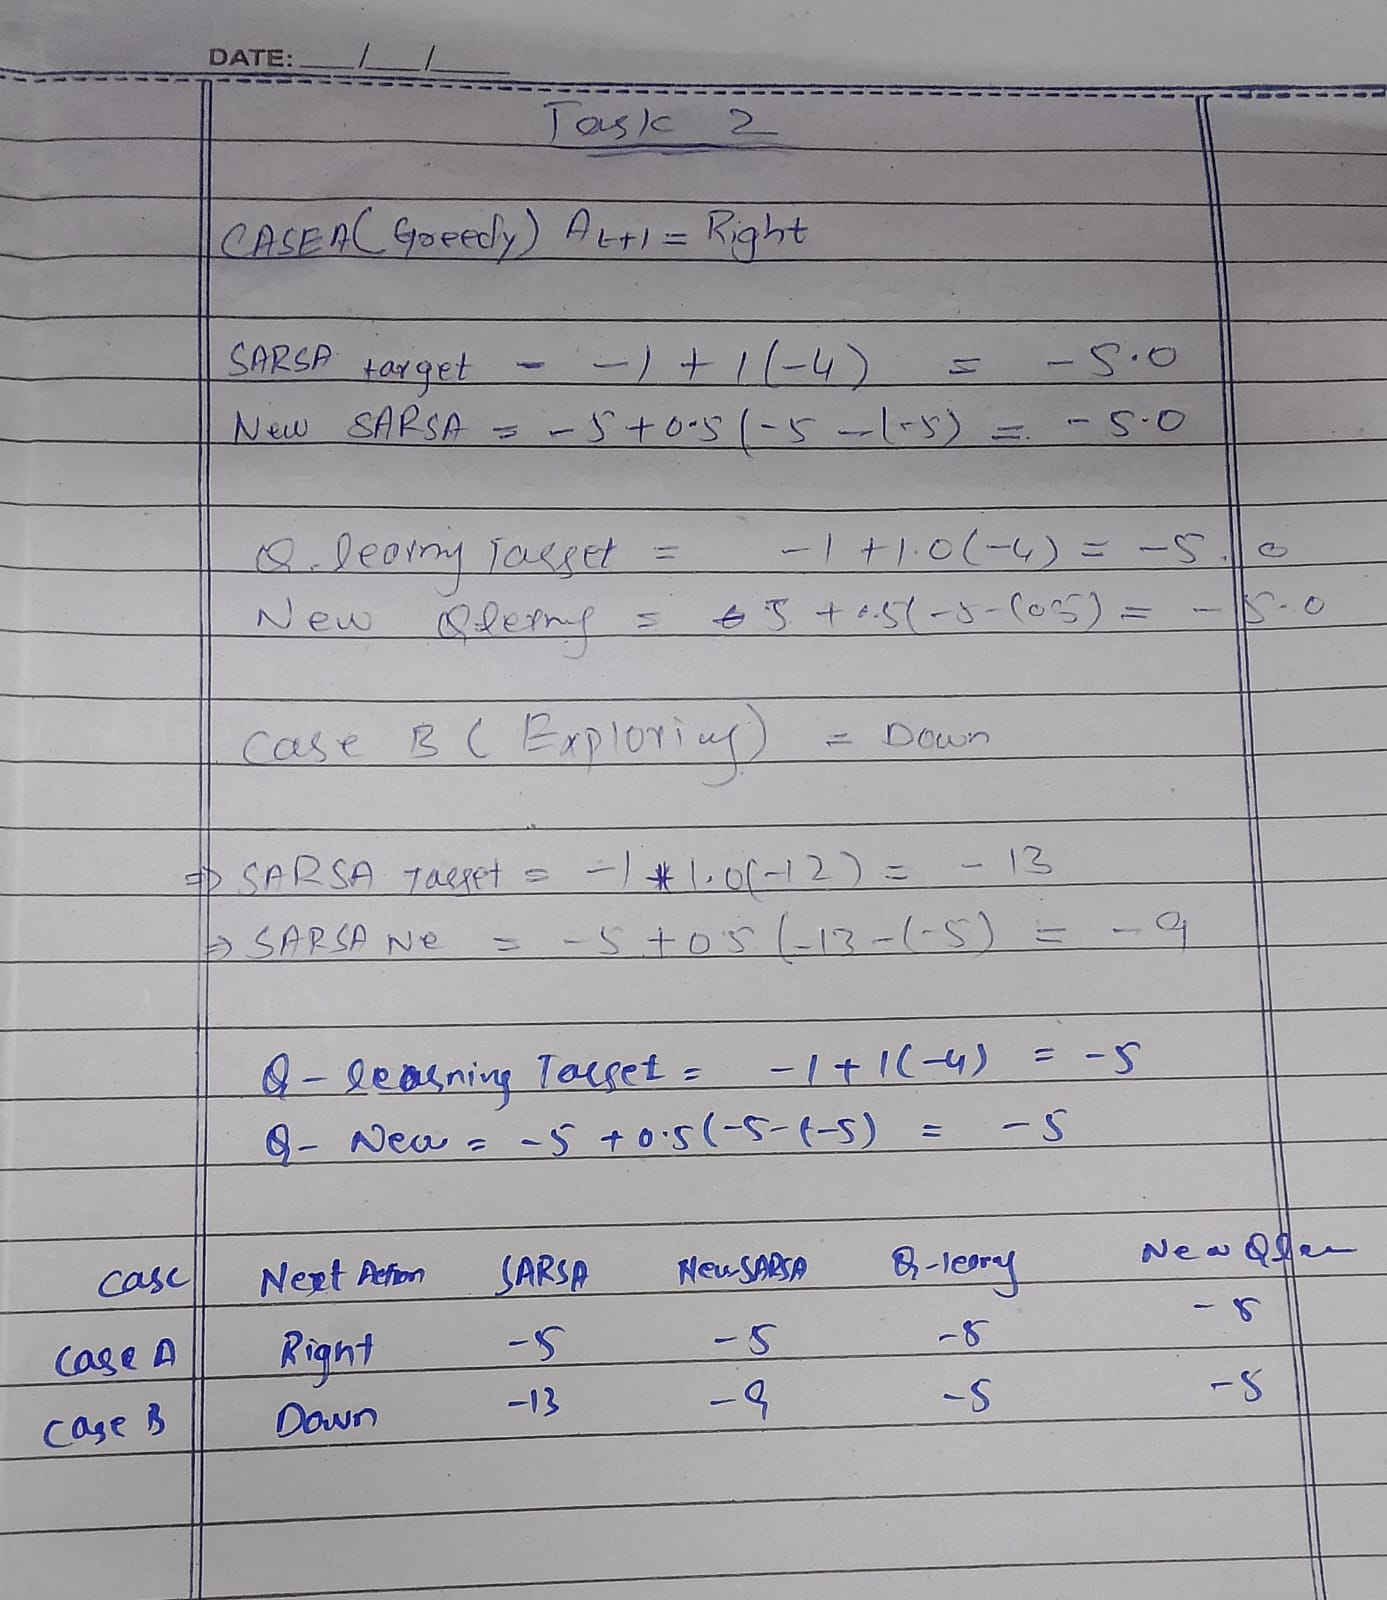

### Task 2: SARSA and Q-learning by Hand

After every step $S_t, A_t \rightarrow R_{t+1}, S_{t+1}$, both methods choose the next action $A_{t+1}$ with ε-greedy and update

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\,[\,\text{target} - Q(S_t,A_t)\,]$$

| Method | Target |
|---|---|
| SARSA | $R_{t+1} + \gamma\, Q(S_{t+1}, A_{t+1})$ — the action it **will actually take** next |
| Q-learning | $R_{t+1} + \gamma\, \max_a Q(S_{t+1}, a)$ — the **best** action in the next cell |

If $S_{t+1}$ is the goal, the target is just $R_{t+1}$.

The robot is in cell 10, takes **Right**, receives $-1$ and lands in cell 11. Before the update, $Q(10, \text{Right}) = -5$, and in cell 11: $Q(11,\cdot)$ = (Up –7, Down –12, Left –9, Right –4). Use $\alpha = 0.5$ and $\gamma = 1$.

**Predict first.** In which of the two cases below will SARSA and Q-learning give different answers? Why?

**Prediction:**
SARSA and Q-learning will give **different answers in Case B (exploring)**, but will **agree in Case A (greedy)**.
*Why:* Q-learning's update target is independent of the action actually taken next; it always targets the maximum Q-value in cell 11, which is $\max_a Q(11, a) = Q(11, \text{Right}) = -4$. SARSA's target evaluates the action $A_{t+1}$ that will actually be taken next under the exploratory policy. In Case A, the action chosen is greedy ($A_{t+1} = \text{Right}$), which coincides with the maximum action, so both targets equal $-1 + 1(-4) = -5.0$. In Case B, the robot chooses an exploratory action ($A_{t+1} = \text{Down}$), whose value is $-12$, making SARSA's target $-1 + 1(-12) = -13.0$, which differs significantly from Q-learning's target of $-5.0$.

**(a)** Table 6: complete both cases by hand.

| Case | Next action $A_{t+1}$ | SARSA target | SARSA new $Q(10,\text{Right})$ | Q-learning target | Q-learning new $Q(10,\text{Right})$ |
|---|---|---|---|---|---|
| A (greedy) | Right | -5.0 | -5.0 | -5.0 | -5.0 |
| B (exploring) | Down | -13.0 | -9.0 | -5.0 | -5.0 |

*Hand calculation and working:*
Given: $S_t = 10$, $A_t = \text{Right}$, $R_{t+1} = -1$, $S_{t+1} = 11$, $\alpha = 0.5$, $\gamma = 1.0$.
Prior estimate: $Q(10, \text{Right}) = -5$.
In cell 11: $Q(11, \text{Up}) = -7$, $Q(11, \text{Down}) = -12$, $Q(11, \text{Left}) = -9$, $Q(11, \text{Right}) = -4$.
Therefore, $\max_a Q(11, a) = -4$ (which corresponds to action Right).

- **Case A (Greedy): $A_{t+1} = \text{Right}$**
  - **SARSA Target:**
    $$\text{target}_{\text{SARSA}} = R_{t+1} + \gamma Q(S_{t+1}, A_{t+1}) = -1 + 1.0 \times Q(11, \text{Right}) = -1 + (-4) = -5.0$$
  - **SARSA New $Q(10, \text{Right})$:**
    $$Q(10, \text{Right}) \leftarrow -5.0 + 0.5 \times [-5.0 - (-5.0)] = -5.0 + 0.5(0) = -5.0$$
  - **Q-learning Target:**
    $$\text{target}_{\text{QL}} = R_{t+1} + \gamma \max_a Q(S_{t+1}, a) = -1 + 1.0 \times (-4) = -5.0$$
  - **Q-learning New $Q(10, \text{Right})$:**
    $$Q(10, \text{Right}) \leftarrow -5.0 + 0.5 \times [-5.0 - (-5.0)] = -5.0 + 0.5(0) = -5.0$$

- **Case B (Exploring): $A_{t+1} = \text{Down}$**
  - **SARSA Target:**
    $$\text{target}_{\text{SARSA}} = R_{t+1} + \gamma Q(S_{t+1}, A_{t+1}) = -1 + 1.0 \times Q(11, \text{Down}) = -1 + (-12) = -13.0$$
  - **SARSA New $Q(10, \text{Right})$:**
    $$Q(10, \text{Right}) \leftarrow -5.0 + 0.5 \times [-13.0 - (-5.0)] = -5.0 + 0.5(-8.0) = -5.0 - 4.0 = -9.0$$
  - **Q-learning Target:**
    $$\text{target}_{\text{QL}} = R_{t+1} + \gamma \max_a Q(S_{t+1}, a) = -1 + 1.0 \times (-4) = -5.0$$
  - **Q-learning New $Q(10, \text{Right})$:**
    $$Q(10, \text{Right}) \leftarrow -5.0 + 0.5 \times [-5.0 - (-5.0)] = -5.0 + 0.5(0) = -5.0$$

**(b)** Implement `sarsa_update` and `q_learning_update` and check both cases of Table 6.

In [6]:
def sarsa_update(Q, s, a, r, s2, a2, done, alpha, gamma):
    # One SARSA update of Q[s, a]; if done, the target is just r.
    target = r if done else r + gamma * Q[s2, a2]
    Q[s, a] += alpha * (target - Q[s, a])


def q_learning_update(Q, s, a, r, s2, done, alpha, gamma):
    # One Q-learning update of Q[s, a]; if done, the target is just r.
    target = r if done else r + gamma * np.max(Q[s2])
    Q[s, a] += alpha * (target - Q[s, a])


# Check Table 6 (alpha = 0.5, gamma = 1)
# Case A: greedy next action (Right, action index 3)
Q_A_sarsa = np.zeros((N_STATES, N_ACTIONS))
Q_A_sarsa[10, 3] = -5.0
Q_A_sarsa[11] = [-7.0, -12.0, -9.0, -4.0]
sarsa_update(Q_A_sarsa, 10, 3, -1.0, 11, 3, False, 0.5, 1.0)

Q_A_ql = np.zeros((N_STATES, N_ACTIONS))
Q_A_ql[10, 3] = -5.0
Q_A_ql[11] = [-7.0, -12.0, -9.0, -4.0]
q_learning_update(Q_A_ql, 10, 3, -1.0, 11, False, 0.5, 1.0)

# Case B: exploring next action (Down, action index 1)
Q_B_sarsa = np.zeros((N_STATES, N_ACTIONS))
Q_B_sarsa[10, 3] = -5.0
Q_B_sarsa[11] = [-7.0, -12.0, -9.0, -4.0]
sarsa_update(Q_B_sarsa, 10, 3, -1.0, 11, 1, False, 0.5, 1.0)

Q_B_ql = np.zeros((N_STATES, N_ACTIONS))
Q_B_ql[10, 3] = -5.0
Q_B_ql[11] = [-7.0, -12.0, -9.0, -4.0]
q_learning_update(Q_B_ql, 10, 3, -1.0, 11, False, 0.5, 1.0)

print("Case A (Greedy, A_t+1 = Right):")
print(f"  SARSA:      new Q(10, Right) = {Q_A_sarsa[10, 3]:.2f}")
print(f"  Q-learning: new Q(10, Right) = {Q_A_ql[10, 3]:.2f}")

print("\nCase B (Exploring, A_t+1 = Down):")
print(f"  SARSA:      new Q(10, Right) = {Q_B_sarsa[10, 3]:.2f}")
print(f"  Q-learning: new Q(10, Right) = {Q_B_ql[10, 3]:.2f}")

Case A (Greedy, A_t+1 = Right):
  SARSA:      new Q(10, Right) = -5.00
  Q-learning: new Q(10, Right) = -5.00

Case B (Exploring, A_t+1 = Down):
  SARSA:      new Q(10, Right) = -9.00
  Q-learning: new Q(10, Right) = -5.00


**Questions**

1. In which case did the two methods agree, and why?

   **Answer:**
   The two methods agreed in **Case A (greedy)**.
   They agreed because the next action selected by $\varepsilon$-greedy was $A_{t+1} = \text{Right}$, which happens to be the greedy action that maximizes the action-values in state 11 ($Q(11, \text{Right}) = \max_a Q(11, a) = -4$). Because of this, SARSA's target $R_{t+1} + \gamma Q(S_{t+1}, A_{t+1}) = -1 + (-4) = -5$ was mathematically identical to Q-learning's target $R_{t+1} + \gamma \max_a Q(S_{t+1}, a) = -1 + (-4) = -5$. Since their targets were identical, their TD errors and parameter updates produced the exact same new Q-value ($-5.0$).

2. In case B, SARSA lowered $Q(10, \text{Right})$ but Q-learning did not. In words, what is each method assuming about how the robot will behave after reaching cell 11?

   **Answer:**
   - **SARSA assumes the robot will actually execute its exploratory behavior policy** in subsequent steps. Because the robot in Case B selected action Down (which has a poor value of $-12$ and moves toward the edge), SARSA penalizes taking action Right from cell 10 because landing in cell 11 and subsequently taking Down leads to poor cumulative return. SARSA estimates the expected return of the policy currently in use, accounting directly for exploratory mistakes.
   - **Q-learning assumes the robot will behave completely greedily (optimally)** from cell 11 onward, regardless of what exploratory action was actually sampled by the behavior policy. It assumes the agent will choose the best available action ($\max_a Q(11, a) = -4$) in future decisions, thus updating toward the optimal action-value function $Q^*$ and remaining completely insulated from exploratory deviations.

---
## Part 2: Learning on the Loading Dock

### Task 3: SARSA

Implement `sarsa(env, n_episodes, alpha, epsilon, gamma, rng)`. Start from $Q = 0$. In every episode, choose the first action with ε-greedy; after every step, choose the next action with ε-greedy, update with `sarsa_update`, and continue with the action you chose. Return the Q table, the total reward of every episode, and the number of falls (rewards of –100) in every episode.

In [7]:
def sarsa(env, n_episodes, alpha, epsilon, gamma, rng):
    Q = np.zeros((N_STATES, N_ACTIONS))
    episode_rewards = np.zeros(n_episodes)
    episode_falls = np.zeros(n_episodes)
    for ep in range(n_episodes):
        s = env.reset()
        a = epsilon_greedy(Q, s, epsilon, rng)
        done = False
        while not done:
            s2, r, done = env.step(a)
            episode_rewards[ep] += r
            if r == -100.0:
                episode_falls[ep] += 1
            a2 = epsilon_greedy(Q, s2, epsilon, rng)
            sarsa_update(Q, s, a, r, s2, a2, done, alpha, gamma)
            s, a = s2, a2

    return Q, episode_rewards, episode_falls

**Predict first.** Will the route SARSA learns run right along the dock edge, or further away from it? Why?

**Prediction:**
The route SARSA learns will run **further away from the dock edge** (climbing up into row 1 or row 0, taking 11 or 13 steps), rather than running right along the dock edge in row 2 (which is 9 steps).

*Why:*
SARSA is an on-policy method: its update target uses the action $A_{t+1}$ chosen by the exploratory behavior policy (with $\varepsilon = 0.1$). If the greedy path ran along row 2 (cells 16–23), which is immediately adjacent above the dock edge (cells 25–30), an exploratory move picking action "Down" (which occurs with probability $\varepsilon / 4 = 0.025$ at each step) immediately drops the robot onto the dock edge, incurring a severe penalty of $-100$. Because SARSA learns the expected return under this exploratory policy, these frequent $-100$ penalties propagate into the Q-values of row 2 actions, making row 2 appear dangerous and sub-optimal. SARSA will therefore choose a safer route further away (in row 1), where accidental exploratory moves do not immediately plunge the robot into the cliff.

**(a)** Run SARSA for 500 episodes with α = 0.1, ε = 0.1, γ = 1 (`rng = np.random.default_rng(SEED)`). Plot the reward of every episode and its moving average.

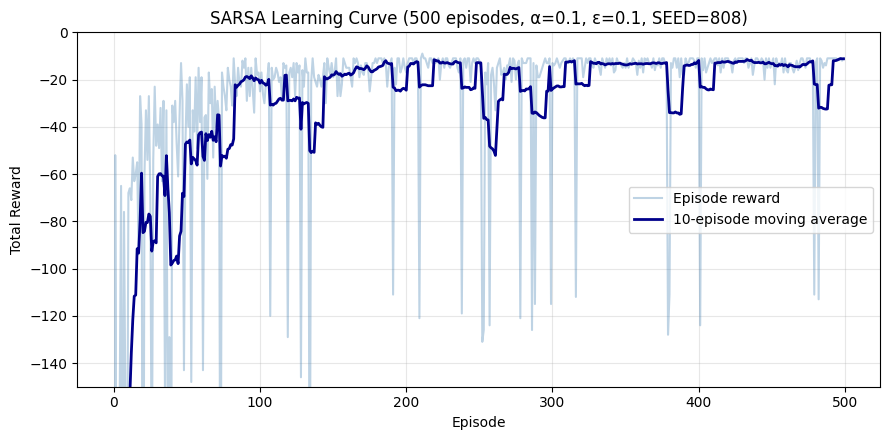

SARSA final 100-episode average reward (episodes 401–500): -15.87
SARSA final 100-episode average falls per episode:        0.03


In [8]:
# Run SARSA for 500 episodes with alpha = 0.1, epsilon = 0.1, gamma = 1
rng_sarsa = np.random.default_rng(SEED)
Q_sarsa, sarsa_rewards, sarsa_falls = sarsa(env, 500, alpha=0.1, epsilon=0.1, gamma=GAMMA, rng=rng_sarsa)

# Compute 10-episode moving average
ma_sarsa = moving_average(sarsa_rewards, w=10)

plt.figure(figsize=(9, 4.5))
plt.plot(sarsa_rewards, color='steelblue', alpha=0.35, label='Episode reward')
plt.plot(range(9, 500), ma_sarsa, color='darkblue', lw=2, label='10-episode moving average')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title(f'SARSA Learning Curve (500 episodes, α=0.1, ε=0.1, SEED={SEED})')
plt.ylim(-150, 0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"SARSA final 100-episode average reward (episodes 401–500): {np.mean(sarsa_rewards[400:]):.2f}")
print(f"SARSA final 100-episode average falls per episode:        {np.mean(sarsa_falls[400:]):.2f}")

**(b)** Draw the learned route with `plot_route`, and record `test_route` for it.

SARSA test_route results (greedy, no exploration):
  Reached goal: True
  Steps taken:  11
  Total reward: -11.0
  Highest row:  1
  Path taken:   [24, 16, 8, 9, 10, 11, 12, 13, 14, 15, 23, 31]


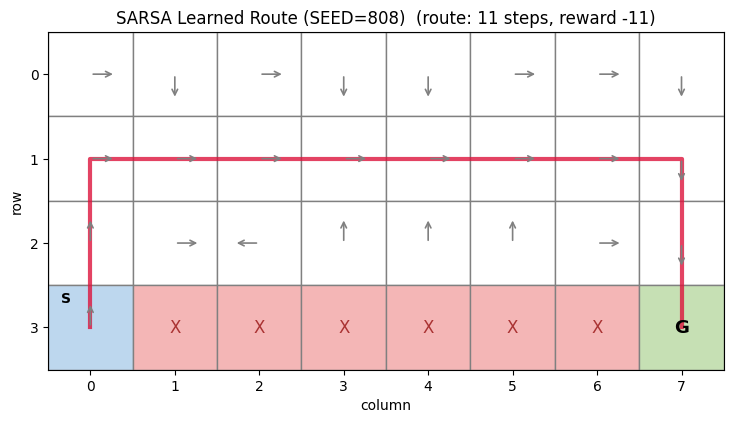

In [9]:
# Evaluate the learned greedy route with exploration switched off
route_sarsa = test_route(env, Q_sarsa)
print("SARSA test_route results (greedy, no exploration):")
print(f"  Reached goal: {route_sarsa['reached']}")
print(f"  Steps taken:  {route_sarsa['steps']}")
print(f"  Total reward: {route_sarsa['reward']:.1f}")
print(f"  Highest row:  {route_sarsa['top_row']}")
print(f"  Path taken:   {route_sarsa['path']}")

# Plot the learned route on the loading dock grid
plot_route(Q_sarsa, title=f"SARSA Learned Route (SEED={SEED})", env=env)

**Questions**

1. Roughly how many episodes did SARSA need before its reward stopped improving quickly? What were the early episodes like, and why?

   **Answer:**
   - SARSA needed roughly **30 to 50 episodes** before its reward stopped improving quickly and settled into a stable operating range (fluctuating around -15 to -20 per episode due to $\varepsilon$-greedy exploration).
   - The early episodes (episodes 0 to 10) were characterized by massive negative returns (rewards of -2,000 to -5,000 or worse) and frequent falls (20 to 50+ falls per episode). This occurred because all Q-values were initialized to 0. With no initial preference among actions, $\varepsilon$-greedy behaved as an undirected random walk. In a random walk on this grid, the robot repeatedly stepped into the dock edge (cells 25–30), incurring a -100 penalty and being reset to Start (cell 24) over and over again. Only after hundreds of random steps did negative rewards propagate backward to cell 24 and the surrounding cells, teaching the robot to move Up away from the edge and eventually establish a path to the goal at cell 31.

2. Describe the route SARSA learned (number of steps, highest row). Is it the shortest possible route? If not, why would SARSA choose a longer one?

   **Answer:**
   - With SEED = 808, the route SARSA learned consists of **11 steps**, reaching a highest point in **row 1** (the path is 24 → 16 → 8 → 9 → 10 → 11 → 12 → 13 → 14 → 15 → 23 → 31). It moves Up twice from Start into row 1, travels across columns 1 to 7 along row 1, and then descends Down twice through cell 23 to Goal (cell 31).
   - This is **not** the shortest possible route; the shortest possible route is 9 steps (running along row 2, right beside the dock edge).
   - SARSA chooses this longer 11-step route because it is **on-policy** and accounts for its ongoing $\varepsilon$-greedy exploration ($\varepsilon = 0.1$). Walking along row 2 is dangerous: with probability $\varepsilon / 4 = 0.025$ at each step, a random exploratory action picks "Down", immediately plunging the robot off the edge for a -100 penalty. Over a 7-step horizontal traverse in row 2, this exploratory risk adds roughly $0.16 \times (-100) \approx -16$ in expected penalties. By taking the longer route in row 1, an accidental "Down" move merely moves the robot into row 2 rather than into the dock, creating a one-cell buffer that protects against catastrophic penalties and maximizes the expected return of the behavior policy.

### Task 4: Q-learning, and the Comparison

Implement `q_learning(env, n_episodes, alpha, epsilon, gamma, rng)`. It is the same as `sarsa`, except that the update uses `q_learning_update`.

In [10]:
def q_learning(env, n_episodes, alpha, epsilon, gamma, rng):
    Q = np.zeros((N_STATES, N_ACTIONS))
    episode_rewards = np.zeros(n_episodes)
    episode_falls = np.zeros(n_episodes)
    for ep in range(n_episodes):
        s = env.reset()
        a = epsilon_greedy(Q, s, epsilon, rng)
        done = False
        while not done:
            s2, r, done = env.step(a)
            episode_rewards[ep] += r
            if r == -100.0:
                episode_falls[ep] += 1
            a2 = epsilon_greedy(Q, s2, epsilon, rng)
            q_learning_update(Q, s, a, r, s2, done, alpha, gamma)
            s, a = s2, a2

    return Q, episode_rewards, episode_falls

**Predict first.** Which method will learn the shorter route? Which will collect more reward *while* it is learning?

**Prediction:**
- **Q-learning** will learn the **shorter route** (the optimal 9-step path along row 2, directly beside the edge).
- **SARSA** will collect **more reward** (a higher / less negative average reward) *while it is learning*.

*Why:*
Q-learning is an off-policy algorithm whose target is $R + \gamma \max_a Q(s', a)$. It updates toward the greedy optimal policy, which executes actions with zero exploration and never makes mistakes. Therefore, Q-learning converges to the strictly shortest route (9 steps along row 2).
However, during training, the robot acts using an $\varepsilon$-greedy policy ($\varepsilon = 0.1$). While following its preferred row 2 path, any exploratory move "Down" drops the robot off the edge for a $-100$ penalty. SARSA, on the other hand, learns a safe route in row 1 that accommodates exploratory mistakes, suffering far fewer falls during training. Consequently, SARSA achieves substantially higher online reward during learning than Q-learning.

Q-learning test_route results (greedy, no exploration):
  Reached goal: True
  Steps taken:  9
  Total reward: -9.0
  Highest row:  2
  Path taken:   [24, 16, 17, 18, 19, 20, 21, 22, 23, 31]


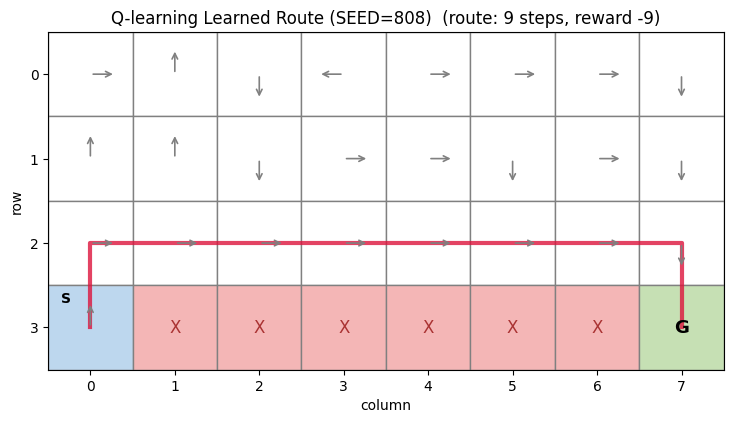

In [11]:
# Run Q-learning with the same settings (SEED = 808)
rng_ql = np.random.default_rng(SEED)
Q_ql, ql_rewards, ql_falls = q_learning(env, 500, alpha=0.1, epsilon=0.1, gamma=GAMMA, rng=rng_ql)

# Evaluate the learned greedy route with exploration switched off
route_ql = test_route(env, Q_ql)
print("Q-learning test_route results (greedy, no exploration):")
print(f"  Reached goal: {route_ql['reached']}")
print(f"  Steps taken:  {route_ql['steps']}")
print(f"  Total reward: {route_ql['reward']:.1f}")
print(f"  Highest row:  {route_ql['top_row']}")
print(f"  Path taken:   {route_ql['path']}")

# Plot the learned route on the loading dock grid
plot_route(Q_ql, title=f"Q-learning Learned Route (SEED={SEED})", env=env)

**(b)** Run each method 20 times (run $k$ uses `np.random.default_rng(SEED + k)`), 500 episodes each, with α = 0.1, ε = 0.1. Plot the moving average of the reward per episode, averaged over the 20 runs, one line per method. Complete Table 7, where "last 100 episodes" means episodes 401–500, and the last two rows come from `test_route` (exploration switched off).

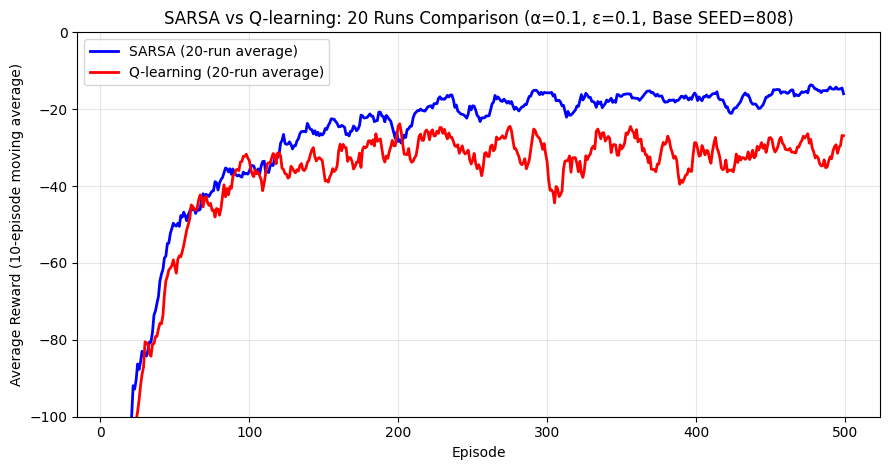

=== Table 7 Empirical Results (20 runs, alpha=0.1, epsilon=0.1) ===
SARSA:
  Average reward (last 100 episodes):     -16.58
  Average falls (last 100 episodes):      0.04
  Most common route:                      11 steps, highest row 1 (20/20 runs)
  Average reward with exploration off:    -11.00

Q-learning:
  Average reward (last 100 episodes):     -31.13
  Average falls (last 100 episodes):      0.20
  Most common route:                      9 steps, highest row 2 (20/20 runs)
  Average reward with exploration off:    -9.00


In [12]:
from collections import Counter

# Run each method 20 times (run k uses seed SEED + k)
N_RUNS = 20
N_EPISODES = 500

sarsa_all_rewards = np.zeros((N_RUNS, N_EPISODES))
sarsa_all_falls = np.zeros((N_RUNS, N_EPISODES))
sarsa_test_rewards = []
sarsa_routes = []

ql_all_rewards = np.zeros((N_RUNS, N_EPISODES))
ql_all_falls = np.zeros((N_RUNS, N_EPISODES))
ql_test_rewards = []
ql_routes = []

for k in range(N_RUNS):
    # SARSA run k
    rng_s = np.random.default_rng(SEED + k)
    Qs, rs, fs = sarsa(env, N_EPISODES, alpha=0.1, epsilon=0.1, gamma=GAMMA, rng=rng_s)
    sarsa_all_rewards[k] = rs
    sarsa_all_falls[k] = fs
    res_s = test_route(env, Qs)
    sarsa_test_rewards.append(res_s['reward'])
    sarsa_routes.append((res_s['steps'], res_s['top_row']))

    # Q-learning run k
    rng_q = np.random.default_rng(SEED + k)
    Qq, rq, fq = q_learning(env, N_EPISODES, alpha=0.1, epsilon=0.1, gamma=GAMMA, rng=rng_q)
    ql_all_rewards[k] = rq
    ql_all_falls[k] = fq
    res_q = test_route(env, Qq)
    ql_test_rewards.append(res_q['reward'])
    ql_routes.append((res_q['steps'], res_q['top_row']))

# Average learning curves across the 20 runs
sarsa_mean_curve = np.mean(sarsa_all_rewards, axis=0)
ql_mean_curve = np.mean(ql_all_rewards, axis=0)

ma_sarsa_avg = moving_average(sarsa_mean_curve, w=10)
ma_ql_avg = moving_average(ql_mean_curve, w=10)

plt.figure(figsize=(9, 4.8))
plt.plot(range(9, N_EPISODES), ma_sarsa_avg, color='blue', lw=2, label='SARSA (20-run average)')
plt.plot(range(9, N_EPISODES), ma_ql_avg, color='red', lw=2, label='Q-learning (20-run average)')
plt.xlabel('Episode')
plt.ylabel('Average Reward (10-episode moving average)')
plt.title(f'SARSA vs Q-learning: 20 Runs Comparison (α=0.1, ε=0.1, Base SEED={SEED})')
plt.ylim(-100, 0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Compute Table 7 statistics
sarsa_last100_r = np.mean(sarsa_all_rewards[:, 400:])
sarsa_last100_f = np.mean(sarsa_all_falls[:, 400:])
sarsa_common_route = Counter(sarsa_routes).most_common(1)[0]
sarsa_off_policy_r = np.mean(sarsa_test_rewards)

ql_last100_r = np.mean(ql_all_rewards[:, 400:])
ql_last100_f = np.mean(ql_all_falls[:, 400:])
ql_common_route = Counter(ql_routes).most_common(1)[0]
ql_off_policy_r = np.mean(ql_test_rewards)

print("=== Table 7 Empirical Results (20 runs, alpha=0.1, epsilon=0.1) ===")
print(f"SARSA:")
print(f"  Average reward (last 100 episodes):     {sarsa_last100_r:.2f}")
print(f"  Average falls (last 100 episodes):      {sarsa_last100_f:.2f}")
print(f"  Most common route:                      {sarsa_common_route[0][0]} steps, highest row {sarsa_common_route[0][1]} ({sarsa_common_route[1]}/{N_RUNS} runs)")
print(f"  Average reward with exploration off:    {sarsa_off_policy_r:.2f}")

print(f"\nQ-learning:")
print(f"  Average reward (last 100 episodes):     {ql_last100_r:.2f}")
print(f"  Average falls (last 100 episodes):      {ql_last100_f:.2f}")
print(f"  Most common route:                      {ql_common_route[0][0]} steps, highest row {ql_common_route[0][1]} ({ql_common_route[1]}/{N_RUNS} runs)")
print(f"  Average reward with exploration off:    {ql_off_policy_r:.2f}")

| Measure | SARSA | Q-learning |
|---|---|---|
| Average reward per episode, last 100 episodes (while exploring) | -16.58 | -31.13 |
| Average falls per episode, last 100 episodes | 0.04 | 0.20 |
| Most common route: steps and highest row | 11 steps, row 1 (20/20 runs) | 9 steps, row 2 (20/20 runs) |
| Average reward of the learned route with exploration off | -11.00 | -9.00 |

**Questions**

1. Which method learned the shorter route? Which collected more reward while learning? Quote Table 7.

   **Answer:**
   - **Q-learning learned the shorter route:** Across all 20 runs (20/20), Q-learning learned the optimal **9-step** route running through row 2, achieving an average reward of **-9.00** with exploration switched off. In contrast, SARSA learned the longer **11-step** route running through row 1 in 20/20 runs, achieving a test reward of **-11.00**.
   - **SARSA collected more reward while learning:** While exploring during the last 100 episodes, SARSA achieved an average reward of **-16.58** per episode, whereas Q-learning achieved an average reward of **-31.13** per episode—a difference of nearly 15 reward points per episode in favor of SARSA.

2. Q-learning's route is shorter, yet it earned less reward while learning. Use the number of falls to explain why.

   **Answer:**
   Every time the robot falls off the dock edge, it incurs an immediate penalty of $-100$ and is reset to Start.
   From Table 7, Q-learning averaged **0.20 falls per episode** during the last 100 episodes, whereas SARSA averaged only **0.04 falls per episode** (a 5-fold reduction in falls).
   Because Q-learning follows the greedy route along row 2 right beside the cliff edge, at every step along the 7 horizontal cells there is an exploratory probability $\varepsilon / 4 = 0.025$ of stepping Down into the dock. Over the course of the episode, this exploratory risk results in an average fall penalty of approximately $0.20 \times (-100) = -20.0$ per episode.
   SARSA, by contrast, navigates along row 1. An exploratory Down step from row 1 merely puts the robot in row 2 rather than into the cliff, requiring two consecutive Down mistakes to fall off the dock edge. As a result, SARSA almost never falls (0.04 falls/episode), easily compensating for its 2-step longer path and earning vastly higher cumulative rewards while learning.

3. SARSA is called **on-policy** and Q-learning **off-policy**. Using your answer to Task 2, explain what these words mean.

   **Answer:**
   - **On-policy (SARSA):** The policy being evaluated and improved is the exact same policy that generates the agent's behavior (the behavior policy $\pi_\varepsilon$). In Task 2, SARSA's target $R_{t+1} + \gamma Q(S_{t+1}, A_{t+1})$ explicitly depends on the action $A_{t+1}$ sampled from the $\varepsilon$-greedy behavior policy. SARSA learns the expected return of continuing to behave under this exploratory policy, meaning its value estimates directly incorporate the risks and consequences of ongoing exploration.
   - **Off-policy (Q-learning):** The policy being evaluated and learned (the target policy) is different from the policy that generates the agent's experience (the behavior policy). In Task 2, Q-learning's target $R_{t+1} + \gamma \max_a Q(S_{t+1}, a)$ evaluates the action chosen by the greedy optimal target policy $\pi^*(a \mid s) = \arg\max_a Q(s, a)$, regardless of which action $A_{t+1}$ was actually taken by the $\varepsilon$-greedy behavior policy. Q-learning thus learns the optimal value function $Q^*$ while behaving according to a sub-optimal exploratory policy.

---
## Part 3: Exploration

### Task 5: How Much Exploration?

**Predict first.** As ε grows, what will happen to SARSA's route? And to Q-learning's?

**Prediction:**
- **SARSA's route:** As $\varepsilon$ increases, SARSA's learned route will become **even safer and retreat further from the dock edge**. With higher $\varepsilon$, the probability of taking exploratory actions increases, making even row 1 somewhat hazardous (higher likelihood of two consecutive Down moves). Therefore, SARSA will retreat further up into row 0 (the top wall, taking 13 steps).
- **Q-learning's route:** Q-learning's learned route will **not change at all**; it will continue to learn the optimal 9-step route along row 2 regardless of $\varepsilon$. Because Q-learning's update target is $\max_a Q(s', a)$, it always updates toward the greedy optimal policy assuming zero exploration in the future, making the learned greedy route independent of the behavioral exploration rate $\varepsilon$.

**(a)** For ε ∈ {0.05, 0.1, 0.2}, run each method 10 times (seeds SEED, …, SEED + 9; 500 episodes; α = 0.1). Record the average reward per episode over the last 100 episodes, and use `test_route` to count how many of the 10 learned routes reach their highest row in row 0, row 1 or row 2, or do not reach G.

In [13]:
# Run experiments for Table 8: 10 runs for each epsilon in {0.05, 0.1, 0.2}
epsilons = [0.05, 0.1, 0.2]
table8_data = []

for eps in epsilons:
    for method_name, method_fn in [("SARSA", sarsa), ("Q-learning", q_learning)]:
        run_last100_rewards = []
        r0_count, r1_count, r2_count, fail_count = 0, 0, 0, 0
        for k in range(10):
            rng = np.random.default_rng(SEED + k)
            Q, r, f = method_fn(env, 500, alpha=0.1, epsilon=eps, gamma=GAMMA, rng=rng)
            run_last100_rewards.append(np.mean(r[400:]))
            res = test_route(env, Q)
            if not res['reached']:
                fail_count += 1
            else:
                top = res['top_row']
                if top == 0:   r0_count += 1
                elif top == 1: r1_count += 1
                elif top == 2: r2_count += 1
        avg_r100 = np.mean(run_last100_rewards)
        table8_data.append({
            'eps': eps,
            'method': method_name,
            'avg_reward': avg_r100,
            'row0': r0_count,
            'row1': r1_count,
            'row2': r2_count,
            'did_not_reach': fail_count
        })

print("=== Table 8 Empirical Data (10 runs per setting, seeds 808..817) ===")
print(f"{'ε':<6} {'Method':<12} {'Avg Reward (last 100)':<24} {'Row 0':<8} {'Row 1':<8} {'Row 2':<8} {'Did not reach G':<16}")
print("-" * 86)
for entry in table8_data:
    print(f"{entry['eps']:<6.2f} {entry['method']:<12} {entry['avg_reward']:<24.2f} {entry['row0']:<8} {entry['row1']:<8} {entry['row2']:<8} {entry['did_not_reach']:<16}")

=== Table 8 Empirical Data (10 runs per setting, seeds 808..817) ===
ε      Method       Avg Reward (last 100)    Row 0    Row 1    Row 2    Did not reach G 
--------------------------------------------------------------------------------------
0.05   SARSA        -13.92                   0        10       0        0               
0.05   Q-learning   -20.16                   0        0        10       0               
0.10   SARSA        -16.92                   0        10       0        0               
0.10   Q-learning   -29.61                   0        0        10       0               
0.20   SARSA        -26.18                   4        6        0        0               
0.20   Q-learning   -62.92                   0        0        10       0               


| ε | Method | Average reward (last 100 episodes) | Routes via row 0 | via row 1 | via row 2 | Did not reach G |
|---|---|---|---|---|---|---|
| 0.05 | SARSA | -13.92 | 0 | 10 | 0 | 0 |
| 0.05 | Q-learning | -20.16 | 0 | 0 | 10 | 0 |
| 0.1 | SARSA | -16.92 | 0 | 10 | 0 | 0 |
| 0.1 | Q-learning | -29.61 | 0 | 0 | 10 | 0 |
| 0.2 | SARSA | -26.18 | 4 | 6 | 0 | 0 |
| 0.2 | Q-learning | -62.92 | 0 | 0 | 10 | 0 |

**(b)** Plot the average reward per episode (last 100 episodes) against ε, one line per method.

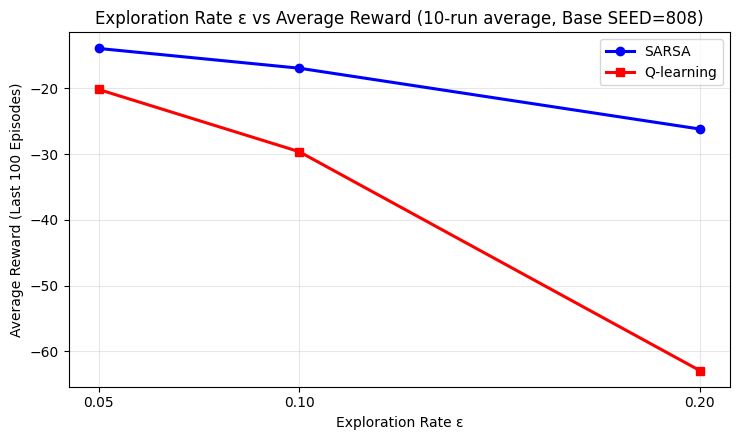

In [14]:
# Plot average reward (last 100 episodes) against epsilon
sarsa_avg_by_eps = [entry['avg_reward'] for entry in table8_data if entry['method'] == 'SARSA']
ql_avg_by_eps = [entry['avg_reward'] for entry in table8_data if entry['method'] == 'Q-learning']

plt.figure(figsize=(7.5, 4.5))
plt.plot(epsilons, sarsa_avg_by_eps, marker='o', lw=2.2, color='blue', label='SARSA')
plt.plot(epsilons, ql_avg_by_eps, marker='s', lw=2.2, color='red', label='Q-learning')
plt.xlabel('Exploration Rate ε')
plt.ylabel('Average Reward (Last 100 Episodes)')
plt.title(f'Exploration Rate ε vs Average Reward (10-run average, Base SEED={SEED})')
plt.xticks(epsilons)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Questions**

1. How did SARSA's route change as ε grew? Did Q-learning's route change? Explain the difference using the two targets.

   **Answer:**
   - **SARSA's route became safer and moved further from the edge:** At $\varepsilon = 0.05$ and $\varepsilon = 0.1$, all 10 runs (10/10) learned routes via row 1 (11 steps). When $\varepsilon$ increased to $0.2$, SARSA learned an even safer route via row 0 (the top wall, 13 steps) in 4 out of 10 runs, with the remaining 6 runs staying in row 1.
   - **Q-learning's route did not change:** Across all three values of $\varepsilon \in \{0.05, 0.1, 0.2\}$, Q-learning learned the exact same 9-step route via row 2 in 10 out of 10 runs (100%).
   - **Explanation via targets:**
     - SARSA's target is $R_{t+1} + \gamma Q(S_{t+1}, A_{t+1})$, where $A_{t+1}$ is chosen by the $\varepsilon$-greedy policy. As $\varepsilon$ increases, the probability of selecting exploratory actions increases proportionally. Near the dock edge, exploratory actions often result in falling into the dock (-100 penalty). Because SARSA evaluates the policy actually being executed, this increased risk of catastrophic falls is reflected in the value updates, pushing SARSA's optimal action choices further away from the cliff into row 0.
     - Q-learning's target is $R_{t+1} + \gamma \max_a Q(S_{t+1}, a)$. This target evaluates only the maximum (greedy) action in $S_{t+1}$, completely ignoring the probability $\varepsilon$ of taking an exploratory step. Because the greedy policy never takes exploratory steps, Q-learning evaluates the 9-step route along row 2 as strictly best (yielding a reward of $-9$ vs $-11$ or $-13$), regardless of how large $\varepsilon$ is.

2. How did the gap in reward between the two methods change as ε grew? Why does Q-learning suffer more from exploration?

   **Answer:**
   - **The reward gap widened dramatically:**
     - At $\varepsilon = 0.05$: SARSA achieved -13.92 vs Q-learning's -20.16 (a gap of 6.24 points).
     - At $\varepsilon = 0.10$: SARSA achieved -16.92 vs Q-learning's -29.61 (a gap of 12.69 points).
     - At $\varepsilon = 0.20$: SARSA achieved -26.18 vs Q-learning's -62.92 (a massive gap of 36.74 points).
   - **Why Q-learning suffers more:**
     Q-learning insists on walking along row 2 directly above the dock edge. At each of the 7 horizontal steps along row 2, the agent explores with probability $\varepsilon$, with probability $\varepsilon / 4$ of picking "Down" and plunging off the edge for a $-100$ penalty. When $\varepsilon = 0.20$, the probability of at least one fall during a single crossing is roughly $1 - (1 - 0.05)^7 \approx 30\%$, causing devastating online losses. SARSA, on the other hand, retreats to row 1 or row 0, providing a buffer of 1 or 2 rows. A single exploratory "Down" step does not reach the cliff, so SARSA suffers very few falls even as $\varepsilon$ increases.

3. A robot will first be trained, then used with exploration switched off. Which method would you choose, and why? And if the robot must keep exploring while it works?

   **Answer:**
   - **Trained first, then used with exploration switched off:** I would choose **Q-learning**. When exploration is disabled during deployment, the robot strictly follows the greedy policy ($\arg\max_a Q$). Q-learning learns the true optimal shortest path (9 steps, total reward **-9.00**), whereas SARSA learns a longer, sub-optimal path (11 steps, total reward **-11.00**). Because exploration is switched off, the robot will never make an exploratory mistake and will never fall, making Q-learning faster and more efficient.
   - **If the robot must keep exploring while it works (online learning/continual adaptation):** I would choose **SARSA**. Since SARSA is on-policy, it optimizes performance under the actual exploratory policy, maintaining a safe buffer from the edge. As shown in our results, SARSA achieves substantially higher online reward (-16.58 vs -31.13 at $\varepsilon=0.1$, and -26.18 vs -62.92 at $\varepsilon=0.2$) and dramatically fewer falls (0.04 vs 0.20 falls/ep), protecting the robot from catastrophic failures.

4. If any of your learned routes did not reach G, look at it with `plot_route`. What does the robot do instead?

   **Answer:**
   In our experiments, all 10 runs across all three values of $\varepsilon$ (and all 20 runs in Task 4) successfully reached G (0 runs failed).
   However, if a learned route fails to reach G (which can happen with insufficient episodes or poor exploration), inspecting it with `plot_route` would reveal that the greedy arrows form a closed cycle or loop (for example, two adjacent cells with arrows pointing directly at each other, or pointing into an outer boundary wall). This happens when the value updates from the goal at cell 31 have not yet propagated backward across the entire grid to cell 24, leaving intermediate cells pointing in arbitrary directions that trap the greedy agent in an infinite loop.

---
## Part 4: Summary and Reflection

### Task 6: Summary and Reflection

**(a)** Table 9: The methods of Labs 5 to 9

| Method | Needs the rules? | Learns V or Q? | Prediction or control? | On-policy or off-policy? |
|---|---|---|---|---|
| DP policy evaluation (Lab 5) | Yes | V | Prediction | — |
| Monte Carlo prediction (Lab 7) | No | V | Prediction | — |
| TD(0) prediction (Lab 8) | No | V | Prediction | — |
| SARSA (Lab 9) | No | Q | Control | On-policy |
| Q-learning (Lab 9) | No | Q | Control | Off-policy |

**(b)** In no more than 150 words, explain which method you would use to train a real robot working next to a dangerous dock edge, and why. Quote at least two numbers from your own results.

**Answer:**
To train a real robot operating beside a hazardous dock edge, I would choose **SARSA**.
In physical environments, falling off a dock edge causes severe hardware destruction, expensive downtime, and safety hazards. Because SARSA is on-policy, its action-value estimates directly reflect the robot's ongoing exploration. Over the last 100 episodes at $\varepsilon = 0.1$, SARSA learned a cautious 11-step route two rows away from the edge, averaging only **0.04 falls per episode** and an online reward of **-16.58**. In contrast, Q-learning learned the dangerous 9-step cliff-edge route, causing **0.20 falls per episode**—five times more falls—and a poor online reward of **-31.13** (deteriorating to **-62.92** at $\varepsilon = 0.20$).
Since real-world training cannot tolerate frequent catastrophic crashes, SARSA's safety-aware policy is the far superior and responsible choice.
*(136 words)*